# Revenue Forecasting
 

# 1. Import libraries

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.statespace.sarimax import SARIMAX

from prophet import Prophet
from sklearn.ensemble import ( RandomForestRegressor, GradientBoostingRegressor)
from xgboost import XGBRegressor

# 2. Import the cleaned daily_model table

In [42]:
df = pd.read_csv("../data_clean/daily_model_table_clean.csv",parse_dates=["date"]).reset_index(drop=True)

In [43]:
df

,date,revenue,orders,average_order_value,orders_lunch,orders_afternoon,orders_dinner,orders_dine_in,orders_delivery,orders_takeaway,...,restaurant_day_type,holiday_name,is_holiday,temperature_avg_c,temp_max_c,temp_min_c,precipitation_mm,is_rainy,weather_condition,is_promo_day
0,2024-01-01,1396.3,40,34.91,16,0,24,23,12,5,...,Quiet,New Year's Day,True,3.8,7.0,1.3,1.3,True,Rain,False
1,2024-01-02,2118.0,56,37.82,24,6,26,30,20,6,...,Quiet,NaN,False,1.3,3.6,-0.5,0.0,False,Cold,False
2,2024-01-03,1527.3,50,30.55,16,2,32,23,15,12,...,Quiet,NaN,False,3.4,5.3,1.9,7.0,True,Rain,False
3,2024-01-04,2532.3,67,37.80,20,1,46,41,17,9,...,Medium,NaN,False,5.7,6.8,4.8,1.0,True,Rain,False
4,2024-01-05,3420.7,91,37.59,21,11,59,52,31,8,...,Peak,NaN,False,-0.1,1.3,-1.2,3.3,True,Rain,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,2025-12-27,4453.8,106,42.02,27,10,69,72,21,13,...,Peak,NaN,False,3.1,5.6,1.0,0.0,False,Normal,False
727,2025-12-28,2529.4,67,37.75,26,5,36,33,28,6,...,Medium,NaN,False,4.8,6.2,3.7,8.9,True,Rain,False
728,2025-12-29,1468.9,43,34.16,12,1,30,25,12,6,...,Quiet,NaN,False,1.9,3.8,0.3,0.0,False,Cold,False
729,2025-12-30,2040.0,56,36.43,16,7,33,31,10,15,...,Quiet,NaN,False,-0.5,1.0,-1.7,0.0,False,Cold,False


# 3. Decomposition

In [44]:
# ============================================
# TIME SERIES DECOMPOSITION 
# CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================

# Make sure the data is sorted by date and date in datetime format,
df = df.copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Keep the final three months as an untouched test period.
train = df.loc[df["date"] < "2025-10-01"].copy()
test = df.loc[df["date"] >= "2025-10-01"].copy()

# Set date as index and select revenue column
# STL used to guide modeling is fitted on training data only.
train_revenue = train.set_index("date")["revenue"].asfreq("D") # Make sure the frequency is daily even though our revenue is already in daily form
train_revenue.isna().sum()

np.int64(0)

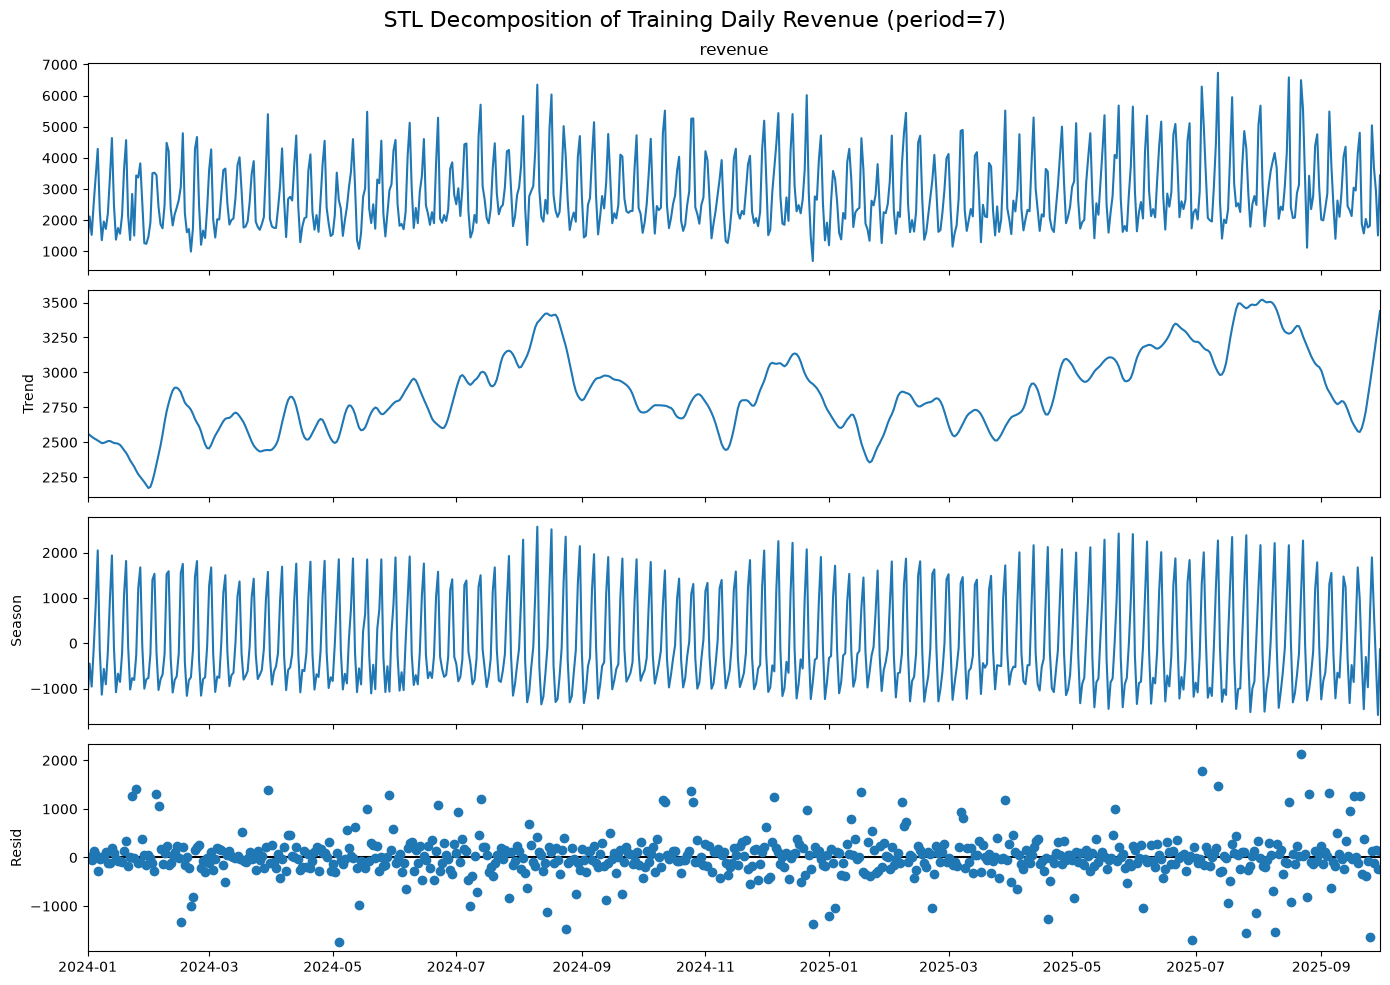

In [45]:
# Fit decomposition only on the training period to avoid using test-period patterns for model decisions.
stl = STL(
    train_revenue, 
    period=7,
    robust=True)

result = stl.fit()

fig = result.plot()
fig.set_size_inches(14, 10)
plt.suptitle("STL Decomposition of Training Daily Revenue (period=7)", fontsize=16)
plt.tight_layout()
plt.show()


STL is fitted on the training period only. STL decomposition reveals a changing underlying revenue trend and a strong weekly seasonal pattern. The seasonal component shows that revenue varies systematically across the seven-day cycle, consistent with the strong performance of the weekday-mean baseline. The residual component is mostly centered around zero but contains several large positive and negative deviations, indicating that trend and weekly seasonality do not explain all daily revenue variation. This supports testing additional predictors such as promotions, holidays and weather in the forecasting models.

In [46]:
seasonal_component = result.seasonal

seasonal_by_day = pd.DataFrame({
    "date": seasonal_component.index,
    "seasonal_effect": seasonal_component.values
})

seasonal_by_day["day_of_week"] = (
    seasonal_by_day["date"].dt.day_name()
)

seasonal_summary = (
    seasonal_by_day
    .groupby("day_of_week")["seasonal_effect"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

seasonal_summary

day_of_week
Monday      -1109.524447
Tuesday      -798.206032
Wednesday    -677.668008
Thursday     -148.472746
Friday       1121.466557
Saturday     1824.104934
Sunday       -212.671212
Name: seasonal_effect, dtype: float64

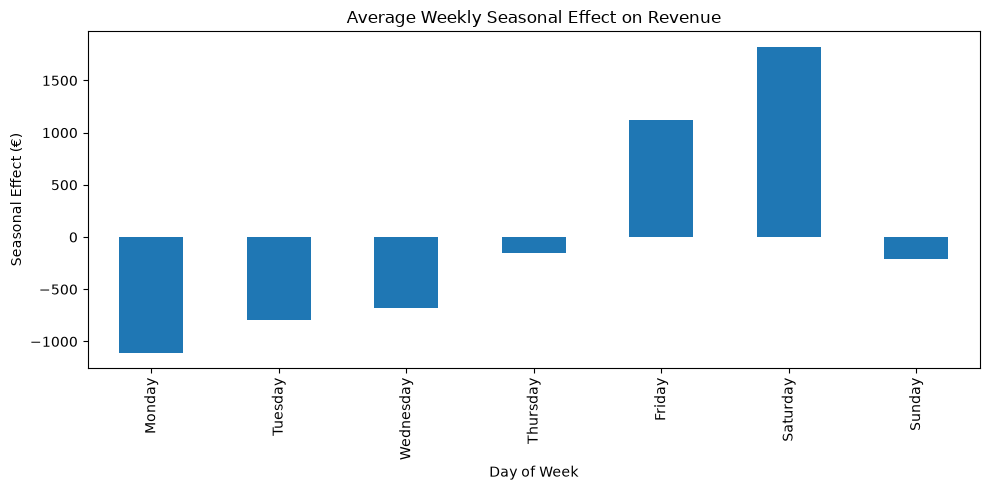

In [47]:
plt.figure(figsize=(10, 5))

seasonal_summary.plot(
    kind="bar"
)

plt.title("Average Weekly Seasonal Effect on Revenue")
plt.xlabel("Day of Week")
plt.ylabel("Seasonal Effect (€)")

plt.tight_layout()
plt.show()

### 3.1 Daily, Weekly and Monthly Revenue Patterns
The forecast target remains daily revenue. These aggregations describe the series at different time scales; they do not define separate forecasting targets or prove seasonality by themselves.

In [48]:
# ============================================
# DAILY / WEEKLY / MONTHLY REVENUE PATTERNS
# ============================================

revenue_daily = df.set_index("date")["revenue"].asfreq("D")
revenue_weekly_all = revenue_daily.resample("W-SUN").agg(["sum", "count"])
revenue_weekly = revenue_weekly_all.loc[revenue_weekly_all["count"] == 7, "sum"]
revenue_monthly = revenue_daily.resample("ME").sum()

print("Daily observations:", revenue_daily.notna().sum())
print("Complete weekly observations:", len(revenue_weekly))
print("Monthly observations:", len(revenue_monthly))
print("Final weekly bin contains", int(revenue_weekly_all["count"].iloc[-1]), "days; excluded from the complete-week plot.")


Daily observations: 731
Complete weekly observations: 104
Monthly observations: 24
Final weekly bin contains 3 days; excluded from the complete-week plot.


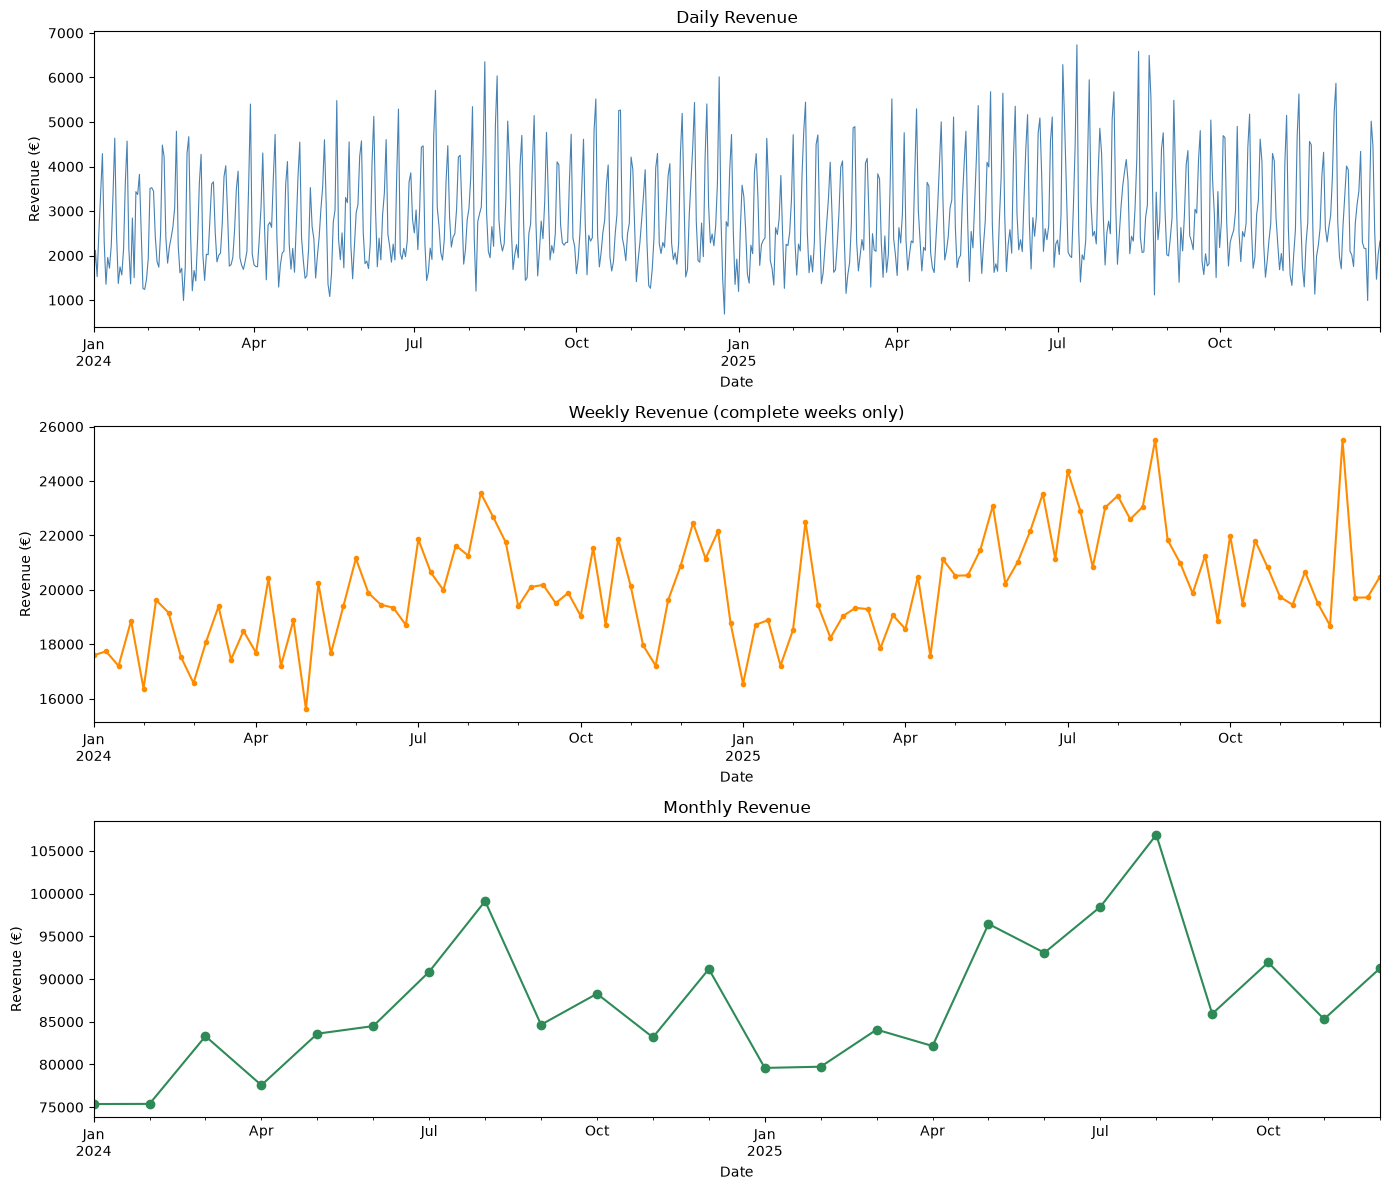

In [49]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
revenue_daily.plot(ax=axes[0], color="steelblue", linewidth=0.8)
axes[0].set(title="Daily Revenue", ylabel="Revenue (€)")
revenue_weekly.plot(ax=axes[1], color="darkorange", marker=".")
axes[1].set(title="Weekly Revenue (complete weeks only)", ylabel="Revenue (€)")
revenue_monthly.plot(ax=axes[2], color="seagreen", marker="o")
axes[2].set(title="Monthly Revenue", ylabel="Revenue (€)")
for ax in axes:
    ax.set_xlabel("Date")
plt.tight_layout()
plt.show()


Each daily point is one day’s revenue, each weekly point is a seven-day total, and each monthly point is a calendar-month total. Weekly and monthly totals naturally have larger euro values than daily revenue. Describe visible changes in level and variability; use the training-only STL and weekday baselines to assess a repeating weekly pattern. Treat the monthly plot as a broad trend description because two years provide few annual cycles.

# 4. Train/Test Split
   - chronological split
   - NO random train_test_split

In [50]:
# ============================================
# TRAIN / TEST SPLIT
# ============================================
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date").copy()

train = df[
    df["date"] < "2025-10-01"
].copy()

test = df[
    df["date"] >= "2025-10-01"
].copy()

In [51]:
# ============================================
# CHECK TRAIN / TEST SPLIT
# ============================================

print("Training period:")
print(train["date"].min(), "to", train["date"].max())

print("\nTesting period:")
print(test["date"].min(), "to", test["date"].max())

print("\nTrain size:", len(train))
print("Test size:", len(test))

# Check for overlap
print("\nDate overlap:", len(set(train["date"]) & set(test["date"])))

# Check for missing dates
print(
    "\nMissing dates in train:",
    train["date"].diff().dt.days.dropna().ne(1).sum()
)

print(
    "Missing dates in test:",
    test["date"].diff().dt.days.dropna().ne(1).sum() # ne is not equal
)

Training period:
2024-01-01 00:00:00 to 2025-09-30 00:00:00

Testing period:
2025-10-01 00:00:00 to 2025-12-31 00:00:00

Train size: 639
Test size: 92

Date overlap: 0

Missing dates in train: 0
Missing dates in test: 0


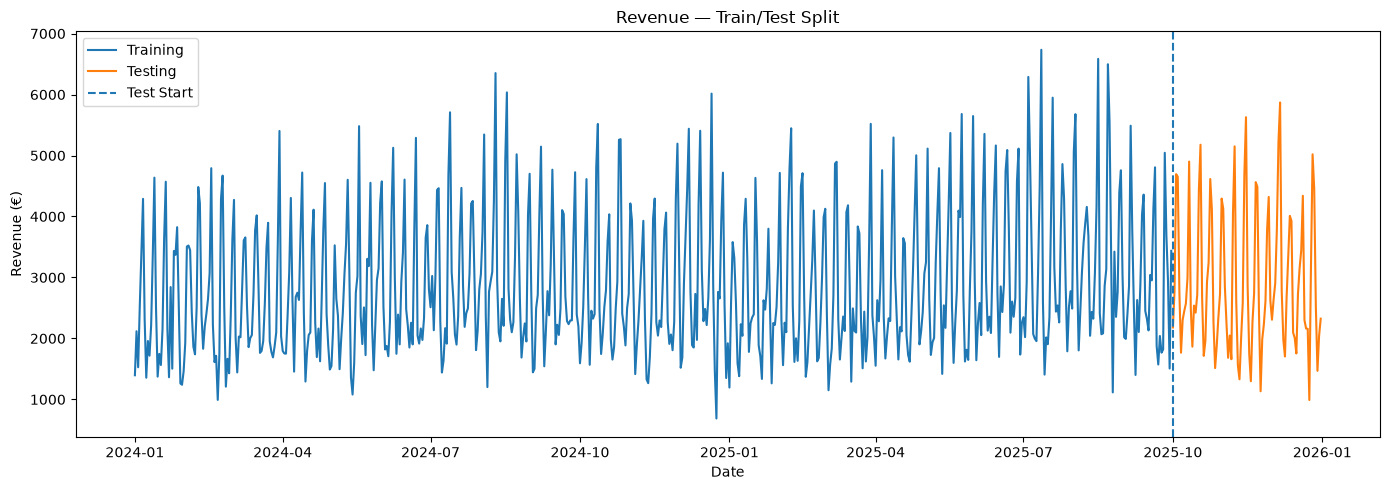

In [52]:
# ============================================
# VISUALIZE TRAIN / TEST SPLIT
# ============================================
plt.figure(figsize=(14, 5))

plt.plot(
    train["date"],
    train["revenue"],
    label="Training"
)

plt.plot(
    test["date"],
    test["revenue"],
    label="Testing"
)

plt.axvline(
    test["date"].iloc[0],
    linestyle="--",
    label="Test Start"
)

plt.title("Revenue — Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Revenue (€)")
plt.legend()

plt.tight_layout()
plt.show()

# 5. Baseline Models and Rolling-Origin Validation
Compare Naive, Seasonal Naive, Mean, Recent Mean, Drift, and Weekday Mean on identical 92-day validation windows, matching the final test horizon. Each fold uses training data available only up to its origin. The final test period remains untouched.

### 5.1. Evaluation Metrics
   - MAE
   - RMSE
   - MAPE

In [53]:
# Evaluation metrics (MAPE is reported only when actual values are nonzero)
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    nonzero = y_true != 0
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100 if nonzero.any() else np.nan,
    }

validation_horizon = 30  # operational forecasting horizon used for model validation
initial_train_days = 365 # minimum history required before the first validation forecast
validation_step = 28  # move the validation origin forward by 28 days

def weekday_mean_forecast(history, forecast_dates):
    means = history.groupby(history["date"].dt.dayofweek)["revenue"].mean()
    return forecast_dates.dt.dayofweek.map(means).to_numpy(dtype=float)

def naive_forecast(history, forecast_dates):
    return np.repeat(float(history["revenue"].iloc[-1]), len(forecast_dates))

def seasonal_naive_forecast(history, forecast_dates, season_length=7):
    last_season = history["revenue"].iloc[-season_length:].to_numpy(dtype=float)
    return np.resize(last_season, len(forecast_dates))

def mean_forecast(history, forecast_dates):
    return np.repeat(float(history["revenue"].mean()), len(forecast_dates))

def recent_mean_forecast(history, forecast_dates, window=28):
    # Four recent weeks: a daily-data counterpart to a recent-period mean.
    return np.repeat(float(history["revenue"].tail(window).mean()), len(forecast_dates))

def drift_forecast(history, forecast_dates):
    values = history["revenue"].to_numpy(dtype=float)
    slope = (values[-1] - values[0]) / (len(values) - 1)
    return values[-1] + slope * np.arange(1, len(forecast_dates) + 1)

baseline_forecasters = {
    "Naive Forecast": naive_forecast,
    "Seasonal Naive": seasonal_naive_forecast,
    "Mean Forecast": mean_forecast,
    "Recent Mean Forecast": recent_mean_forecast,
    "Drift Forecast": drift_forecast,
    "Weekday Mean": weekday_mean_forecast,
}


### 5.2 Baseline Models

In [54]:
# evaluation engine
def evaluate_forecaster(forecaster, train_data, horizon, initial_days, step, model_name="Model"):
    data = train_data.sort_values("date").reset_index(drop=True)
    rows = []
    for origin in range(initial_days, len(data) - horizon + 1, step):
        history = data.iloc[:origin].copy()
        valid = data.iloc[origin:origin + horizon].copy()
        pred = forecaster(history, valid["date"])
        row = {"model": model_name, "origin": history["date"].iloc[-1]}
        row.update(calculate_metrics(valid["revenue"].to_numpy(), pred))
        rows.append(row)
    return pd.DataFrame(rows)

# baseline validation
baseline_folds = pd.concat([
    evaluate_forecaster(fn, train, validation_horizon, initial_train_days, validation_step, name)
    for name, fn in baseline_forecasters.items()
], ignore_index=True)

baseline_summary = (baseline_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
                    .agg(["mean", "std"]).round(2))
baseline_summary


MAE             RMSE         MAPE (%)      
                         mean     std     mean     std     mean   std
model                                                                
Drift Forecast        1350.26  221.95  1757.92  237.06    39.39  6.07
Mean Forecast          919.95   81.74  1176.34  171.94    33.41  4.36
Naive Forecast        1354.16  220.44  1761.41  236.76    39.50  5.95
Recent Mean Forecast   951.67  102.94  1170.08  137.38    36.12  5.43
Seasonal Naive         552.67  143.72   717.66  173.68    19.76  5.02
Weekday Mean           429.43   93.07   559.83  150.79    14.76  2.23

Lower MAE/RMSE/MAPE indicates smaller errors; MAE is the primary selection metric because it is in euros/dollar and easier to interpret. The fold standard deviation shows how much performance varies across time.

Baseline benchmark
────────────────────────
* Weekday Mean
  
- MAE   = €429.43
- RMSE  = €559.83
- MAPE  = 14.76 %

# 6. Traditional Forecasting Models

In [55]:
# Moving Average: use the previous 7 days to forecast the next day, then recursively forecasts the remaining days
def moving_average_forecast(history, forecast_dates, window=7):
    values = list(history["revenue"].astype(float))
    predictions = []
    for _ in forecast_dates:
        prediction = float(np.mean(values[-window:]))
        predictions.append(prediction)
        values.append(prediction)
    return np.asarray(predictions)

# Auto Regressive forecast
def ar_forecast(history, forecast_dates, lags=7):
    # A linear autoregression fitted on the seven prior daily revenue values.
    values = history.sort_values("date")["revenue"].to_numpy(dtype=float)
    X = np.array([values[t - lags:t][::-1] for t in range(lags, len(values))])
    y = values[lags:]
    fitted = LinearRegression().fit(X, y)
    predictions = []
    history_values = list(values)
    for _ in forecast_dates:
        prediction = float(fitted.predict(np.array(history_values[-lags:][::-1]).reshape(1, -1))[0])
        predictions.append(prediction)
        history_values.append(prediction)
    return np.asarray(predictions)

# ARIMA
def arima_forecast(history, forecast_dates):
    # ARIMA(1,0,1): the non-seasonal version of the state-space model.
    y = history.set_index("date")["revenue"].asfreq("D") # makes the series explicitly daily
    model = SARIMAX(y, order=(1, 0, 1), trend="t", # "t" adds a linear time trend
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False, maxiter=100)
    return np.asarray(fitted.forecast(steps=len(forecast_dates)), dtype=float)

# SARIMA
def sarima_forecast(history, forecast_dates):
    y = history.set_index("date")["revenue"].asfreq("D")
    model = SARIMAX(y, order=(1, 0, 1), seasonal_order=(1, 0, 1, 7),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False, maxiter=100)
    return np.asarray(fitted.forecast(steps=len(forecast_dates)), dtype=float)

# Put the traditional models into a dictionary
traditional_forecasters = {
    "Moving Average — 7 Days": moving_average_forecast,
    "AR — 7 Lags": ar_forecast,
    "ARIMA (1,0,1)": arima_forecast,
    "SARIMA — Weekly": sarima_forecast,
}

# Run rolling validation
traditional_folds = pd.concat([
    evaluate_forecaster(fn, train, validation_horizon, initial_train_days, validation_step, name)
    for name, fn in traditional_forecasters.items()
], ignore_index=True)
traditional_summary = (traditional_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]].agg(["mean", "std"]).round(2))
traditional_summary
                       


MAE             RMSE         MAPE (%)       
                            mean     std     mean     std     mean    std
model                                                                    
AR — 7 Lags               526.05   76.73   703.82  144.57    18.65   2.42
ARIMA (1,0,1)            1566.72  120.49  1781.03  132.91    71.93  11.71
Moving Average — 7 Days   930.90  132.35  1160.66  150.35    34.59   5.19
SARIMA — Weekly           407.98   70.47   532.29  116.66    14.87   3.60

# 7. Baseline vs Traditional

In [56]:
baseline_validation_summary = (
    baseline_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .mean()
    .reset_index()
)

traditional_validation_summary = (
    traditional_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .mean()
    .reset_index()
)

validation_comparison = pd.concat(
    [
        baseline_validation_summary,
        traditional_validation_summary
    ],
    ignore_index=True
)

validation_comparison = (
    validation_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

validation_comparison.round(2)

,model,MAE,RMSE,MAPE (%)
0,SARIMA — Weekly,407.98,532.29,14.87
1,Weekday Mean,429.43,559.83,14.76
2,AR — 7 Lags,526.05,703.82,18.65
3,Seasonal Naive,552.67,717.66,19.76
4,Mean Forecast,919.95,1176.34,33.41
5,Moving Average — 7 Days,930.90,1160.66,34.59
6,Recent Mean Forecast,951.67,1170.08,36.12
7,Drift Forecast,1350.26,1757.92,39.39
8,Naive Forecast,1354.16,1761.41,39.50
9,"ARIMA (1,0,1)",1566.72,1781.03,71.93


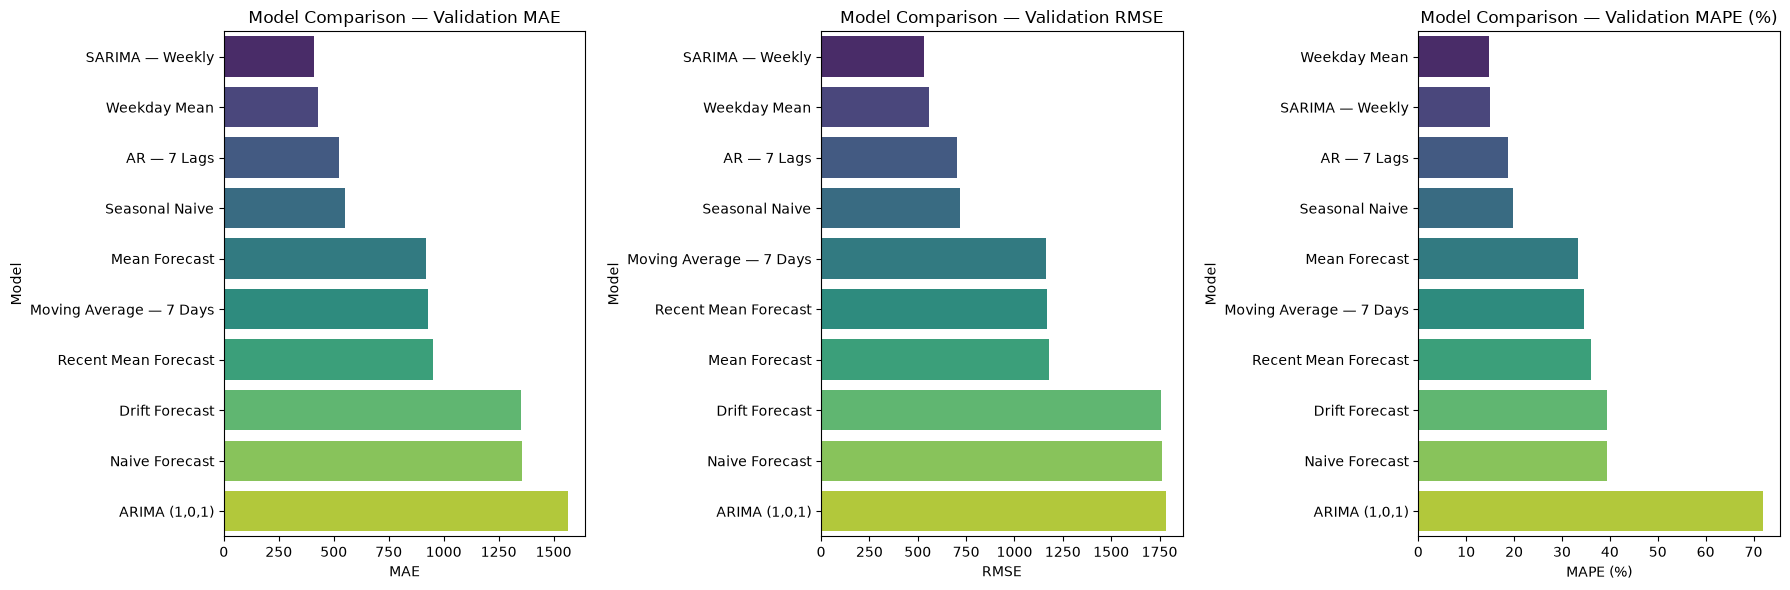

In [57]:
# ============================================
# VISUALIZE Model Comparision
# ============================================
metrics = [
    "MAE",
    "RMSE",
    "MAPE (%)"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

for ax, metric in zip(axes, metrics):

    plot_data = (
        validation_comparison
        .sort_values(metric)
    )

    sns.barplot(
        data=plot_data,
        x=metric,
        y="model",
        hue="model",
        legend=False,
        palette="viridis",
        ax=ax
    )

    ax.set_title(
        f"Model Comparison — Validation {metric}"
    )

    ax.set_xlabel(metric)
    ax.set_ylabel("Model")

plt.tight_layout()
plt.show()

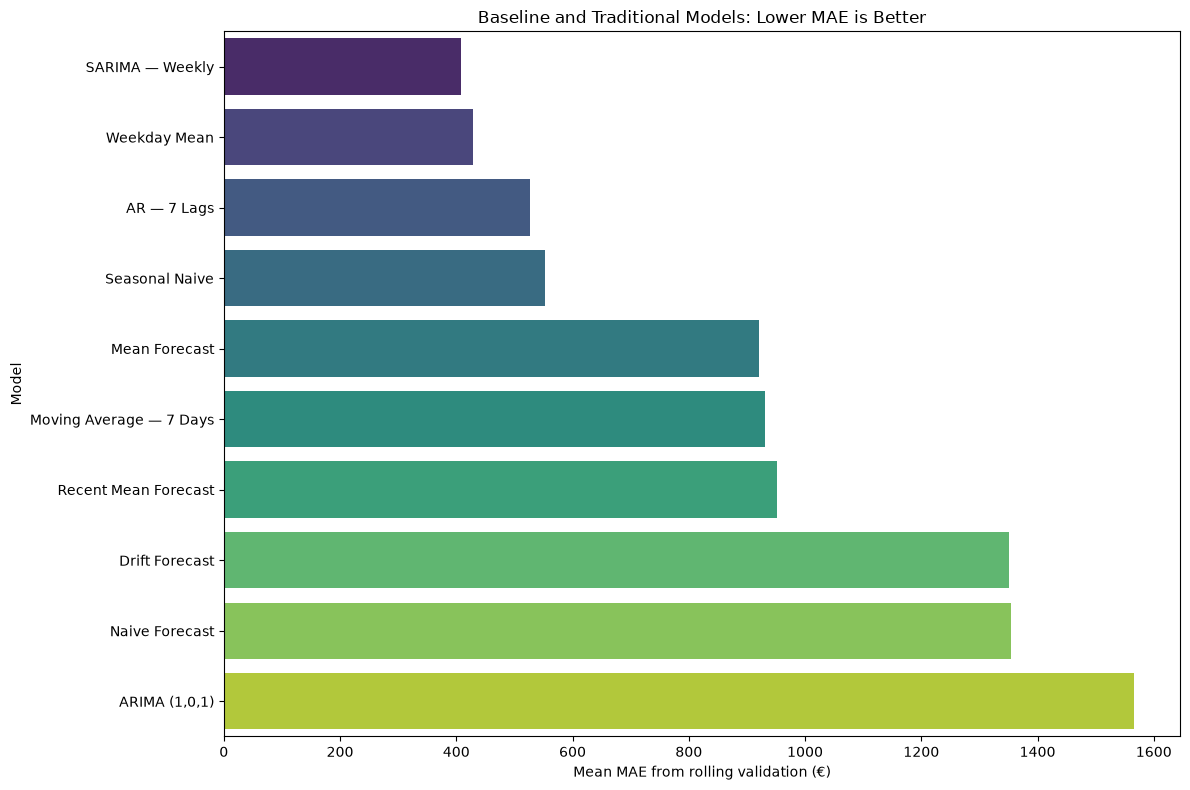

In [58]:
# ============================================
# VISUALIZE Model Comparision with MAE metrics
# ============================================

all_folds = pd.concat([baseline_folds, traditional_folds], ignore_index=True)
model_comparison = (all_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
                    .agg(["mean", "std"]))
model_comparison.columns = [f"{metric}_{stat}" for metric, stat in model_comparison.columns]
model_comparison = model_comparison.sort_values("MAE_mean").round(2)

comparison_table = (model_comparison.reset_index()
                    .rename(columns={
                        "model": "Model",
                        "MAE_mean": "MAE (€)",
                        "RMSE_mean": "RMSE (€)",
                        "MAPE (%)_mean": "MAPE (%)",
                        "MAE_std": "MAE SD (€)",
                        "RMSE_std": "RMSE SD (€)",
                        "MAPE (%)_std": "MAPE SD (%)",
                    }))

plt.figure(figsize=(12, 8))
sns.barplot(
    data=comparison_table.sort_values("MAE (€)"),
    x="MAE (€)",
    y="Model",
    hue="Model",
    legend=False,
    palette="viridis"
)
plt.title("Baseline and Traditional Models: Lower MAE is Better")
plt.xlabel("Mean MAE from rolling validation (€)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


MAE was selected as the primary evaluation metric because it provides an interpretable measure of average daily revenue error in euros. RMSE was used as a secondary metric to account for larger forecasting errors, while MAPE was used as a supporting percentage-based metric. Based on rolling-origin validation, SARIMA achieved the lowest MAE and RMSE, while Weekday Mean achieved a marginally lower MAPE. Therefore, ```SARIMA-weekly was considered the stronger model at this stage.```

## 6. Prophet

This notebook compares a revenue-only Prophet model with a weekly-seasonality Prophet model. Weather, holiday, calendar, and promotion inputs are tested in the dedicated external-feature models later in the notebook.

In [59]:
# baseline prophet 
def prophet_forecast(history, forecast_dates, weekly_seasonality=False):
    ptrain = history[["date", "revenue"]].rename(columns={"date": "ds", "revenue": "y"})
    model = Prophet(
        weekly_seasonality=weekly_seasonality,
        yearly_seasonality=False,  # under two years of training history: avoid unstable annual seasonality
        daily_seasonality=False,
        seasonality_mode="additive",
        interval_width=0.80,
    )
    model.fit(ptrain)
    future = pd.DataFrame({"ds": pd.to_datetime(forecast_dates)})
    forecast = model.predict(future)
    return forecast["yhat"].to_numpy()

def prophet_revenue_only(history, dates):
    return prophet_forecast(history, dates, weekly_seasonality=False)

def prophet_weekly(history, dates):
    return prophet_forecast(history, dates, weekly_seasonality=True)

# Evaluate both
prophet_folds = pd.concat([
    evaluate_forecaster(prophet_revenue_only, train, validation_horizon, initial_train_days, validation_step, "Prophet — Revenue Only"),
    evaluate_forecaster(prophet_weekly, train, validation_horizon, initial_train_days, validation_step, "Prophet — Weekly Seasonality"),
], ignore_index=True)

prophet_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]].agg(["mean", "std"]).round(2)


18:11:22 - cmdstanpy - INFO - Chain [1] start processing
18:11:22 - cmdstanpy - INFO - Chain [1] done processing
18:11:22 - cmdstanpy - INFO - Chain [1] start processing
18:11:22 - cmdstanpy - INFO - Chain [1] done processing
18:11:22 - cmdstanpy - INFO - Chain [1] start processing
18:11:22 - cmdstanpy - INFO - Chain [1] done processing
18:11:22 - cmdstanpy - INFO - Chain [1] start processing
18:11:22 - cmdstanpy - INFO - Chain [1] done processing
18:11:22 - cmdstanpy - INFO - Chain [1] start processing
18:11:22 - cmdstanpy - INFO - Chain [1] done processing
18:11:22 - cmdstanpy - INFO - Chain [1] start processing
18:11:22 - cmdstanpy - INFO - Chain [1] done processing
18:11:22 - cmdstanpy - INFO - Chain [1] start processing
18:11:22 - cmdstanpy - INFO - Chain [1] done processing
18:11:22 - cmdstanpy - INFO - Chain [1] start processing
18:11:22 - cmdstanpy - INFO - Chain [1] done processing
18:11:22 - cmdstanpy - INFO - Chain [1] start processing
18:11:22 - cmdstanpy - INFO - Chain [1]

MAE            RMSE         MAPE (%)      
                                mean    std     mean     std     mean   std
model                                                                      
Prophet — Revenue Only        957.70  74.90  1174.79  139.24    36.68  5.77
Prophet — Weekly Seasonality  418.27  63.72   538.31  110.58    14.94  2.92

In [60]:
def prophet_external_forecast(
    history,
    valid,
    regressors,
    weekly_seasonality=True
):
    train_prophet = (
        history[["date", "revenue"] + regressors]
        .rename(
            columns={
                "date": "ds",
                "revenue": "y"
            }
        )
    )

    valid_prophet = (
        valid[["date"] + regressors]
        .rename(columns={"date": "ds"})
    )

    model = Prophet(
        weekly_seasonality=weekly_seasonality,
        yearly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode="additive",
        interval_width=0.80,
    )

    for regressor in regressors:
        model.add_regressor(regressor)

    model.fit(train_prophet)

    forecast = model.predict(valid_prophet)

    return forecast["yhat"].to_numpy()


Revenue + Calendar

In [61]:
# prophet evaluate function
def evaluate_prophet_external(
    forecaster,
    train_data,
    horizon,
    initial_days,
    step,
    model_name="Model"
):
    data = (
        train_data
        .sort_values("date")
        .reset_index(drop=True)
    )

    rows = []

    for origin in range(
        initial_days,
        len(data) - horizon + 1,
        step
    ):

        history = data.iloc[:origin].copy()

        valid = data.iloc[
            origin:origin + horizon
        ].copy()

        pred = forecaster(
            history,
            valid
        )

        row = {
            "model": model_name,
            "origin": history["date"].iloc[-1]
        }

        row.update(
            calculate_metrics(
                valid["revenue"].to_numpy(),
                pred
            )
        )

        rows.append(row)

    return pd.DataFrame(rows)

In [62]:
calendar_regressors = [
    "is_holiday",
    "is_promo_day"
]

def prophet_calendar(
    history,
    valid
):
    return prophet_external_forecast(
        history,
        valid,
        regressors=calendar_regressors,
        weekly_seasonality=True
    )

In [63]:
# Evaluate the model Prophet — Revenue + Calendar
prophet_calendar_folds = evaluate_prophet_external(
    prophet_calendar,
    train,
    validation_horizon,
    initial_train_days,
    validation_step,
    "Prophet — Revenue + Calendar"
)

prophet_calendar_summary = (
    prophet_calendar_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

prophet_calendar_summary

18:11:23 - cmdstanpy - INFO - Chain [1] start processing
18:11:23 - cmdstanpy - INFO - Chain [1] done processing
18:11:23 - cmdstanpy - INFO - Chain [1] start processing
18:11:23 - cmdstanpy - INFO - Chain [1] done processing
18:11:23 - cmdstanpy - INFO - Chain [1] start processing
18:11:23 - cmdstanpy - INFO - Chain [1] done processing
18:11:23 - cmdstanpy - INFO - Chain [1] start processing
18:11:23 - cmdstanpy - INFO - Chain [1] done processing
18:11:23 - cmdstanpy - INFO - Chain [1] start processing
18:11:23 - cmdstanpy - INFO - Chain [1] done processing
18:11:23 - cmdstanpy - INFO - Chain [1] start processing
18:11:23 - cmdstanpy - INFO - Chain [1] done processing
18:11:23 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1]

MAE          RMSE         MAPE (%)      
                                mean    std   mean     std     mean   std
model                                                                    
Prophet — Revenue + Calendar  418.53  60.52  544.5  105.74    14.96  3.53

Revenue + Calendar + Weather

In [64]:
calendar_weather_regressors = [
    "is_weekend",
    "is_holiday",
    "is_promo_day",
    "temperature_avg_c",
    "precipitation_mm",
    "is_rainy"
]

def prophet_calendar_weather(
    history,
    valid
):
    return prophet_external_forecast(
        history,
        valid,
        regressors=calendar_weather_regressors,
        weekly_seasonality=True
    )

# Evaluate model Prophet — Calendar + Weather
prophet_weather_folds = evaluate_prophet_external(
    prophet_calendar_weather,
    train,
    validation_horizon,
    initial_train_days,
    validation_step,
    "Prophet — Calendar + Weather"
)

prophet_weather_summary = (
    prophet_weather_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

prophet_weather_summary

18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1] done processing
18:11:24 - cmdstanpy - INFO - Chain [1] start processing
18:11:24 - cmdstanpy - INFO - Chain [1]

MAE          RMSE         MAPE (%)      
                                mean    std   mean     std     mean   std
model                                                                    
Prophet — Calendar + Weather  400.86  68.29  525.2  115.97    14.85  4.17

Combine all four Prophet models

In [65]:
prophet_all_folds = pd.concat(
    [
        prophet_folds,
        prophet_calendar_folds,
        prophet_weather_folds
    ],
    ignore_index=True
)

prophet_all_summary = (
    prophet_all_folds
    .groupby("model")[[
        "MAE",
        "RMSE",
        "MAPE (%)"
    ]]
    .agg(["mean", "std"])
    .round(2)
)

prophet_all_summary

MAE            RMSE         MAPE (%)      
                                mean    std     mean     std     mean   std
model                                                                      
Prophet — Calendar + Weather  400.86  68.29   525.20  115.97    14.85  4.17
Prophet — Revenue + Calendar  418.53  60.52   544.50  105.74    14.96  3.53
Prophet — Revenue Only        957.70  74.90  1174.79  139.24    36.68  5.77
Prophet — Weekly Seasonality  418.27  63.72   538.31  110.58    14.94  2.92

Create a clean Prophet comparison table

In [66]:
prophet_comparison = (
    prophet_all_folds
    .groupby("model")[[
        "MAE",
        "RMSE",
        "MAPE (%)"
    ]]
    .mean()
    .sort_values("MAE")
    .round(2)
)

prophet_comparison

,MAE,RMSE,MAPE (%)
model,,,
Prophet — Calendar + Weather,400.86,525.20,14.85
Prophet — Weekly Seasonality,418.27,538.31,14.94
Prophet — Revenue + Calendar,418.53,544.50,14.96
Prophet — Revenue Only,957.70,1174.79,36.68


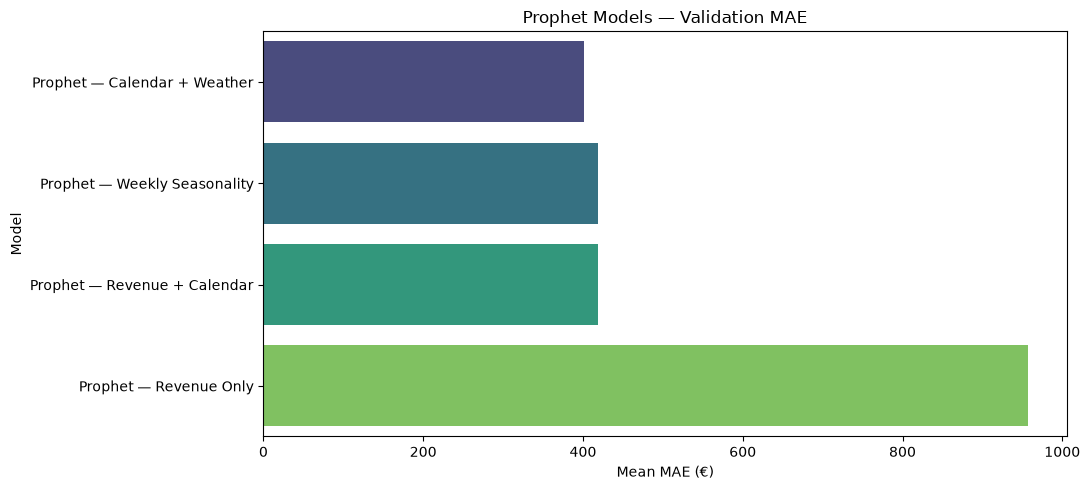

In [67]:
plot_data = (
    prophet_comparison
    .reset_index()
    .sort_values("MAE")
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_data,
    x="MAE",
    y="model",
    hue="model",
    legend=False,
    palette="viridis"
)

plt.title("Prophet Models — Validation MAE")
plt.xlabel("Mean MAE (€)")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

For now, `Prophet with Calendar + Weather` is currently the best model, but only by €7.12 MAE versus SARIMA-weekly.

# 7. SARIMAX

In [68]:
def make_sarimax_exog(dates):
    dates = pd.DatetimeIndex(dates)
    return pd.DataFrame({
        "is_weekend": (dates.dayofweek >= 5).astype(int),
        "annual_sin": np.sin(2 * np.pi * dates.dayofyear / 365.25),
        "annual_cos": np.cos(2 * np.pi * dates.dayofyear / 365.25),
    }, index=dates)

def sarimax_forecast(history, forecast_dates):
    y = history.set_index("date")["revenue"].asfreq("D")
    train_exog = make_sarimax_exog(y.index)
    future_exog = make_sarimax_exog(pd.to_datetime(forecast_dates))
    model = SARIMAX(y, exog=train_exog, order=(1, 0, 1), seasonal_order=(1, 0, 1, 7),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False, maxiter=100)
    return np.asarray(fitted.forecast(steps=len(forecast_dates), exog=future_exog), dtype=float)

sarimax_folds = evaluate_forecaster(sarimax_forecast, train, validation_horizon,
                                    initial_train_days, validation_step, "SARIMAX — Calendar + Weekly")
sarimax_summary = (sarimax_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]].agg(["mean", "std"]).round(2))
sarimax_summary


/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


MAE           RMSE         MAPE (%)      
                               mean    std    mean     std     mean   std
model                                                                    
SARIMAX — Calendar + Weekly  432.96  72.99  563.79  108.44    14.74  2.06

### Models comparison

In [69]:
pre_ml_comparison = pd.concat(
    [
        baseline_folds,
        traditional_folds,
        prophet_all_folds,
        sarimax_folds
    ],
    ignore_index=True
)

pre_ml_leaderboard = (
    pre_ml_comparison
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .mean()
    .sort_values("MAE")
    .round(2)
)

pre_ml_leaderboard

,MAE,RMSE,MAPE (%)
model,,,
Prophet — Calendar + Weather,400.86,525.20,14.85
SARIMA — Weekly,407.98,532.29,14.87
Prophet — Weekly Seasonality,418.27,538.31,14.94
Prophet — Revenue + Calendar,418.53,544.50,14.96
Weekday Mean,429.43,559.83,14.76
SARIMAX — Calendar + Weekly,432.96,563.79,14.74
AR — 7 Lags,526.05,703.82,18.65
Seasonal Naive,552.67,717.66,19.76
Mean Forecast,919.95,1176.34,33.41


In [70]:
pre_ml_stability = (
    pre_ml_comparison
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .std()
    .sort_values("MAE")
    .round(2)
)

pre_ml_stability

,MAE,RMSE,MAPE (%)
model,,,
Prophet — Revenue + Calendar,60.52,105.74,3.53
Prophet — Weekly Seasonality,63.72,110.58,2.92
Prophet — Calendar + Weather,68.29,115.97,4.17
SARIMA — Weekly,70.47,116.66,3.60
SARIMAX — Calendar + Weekly,72.99,108.44,2.06
Prophet — Revenue Only,74.90,139.24,5.77
AR — 7 Lags,76.73,144.57,2.42
Mean Forecast,81.74,171.94,4.36
Weekday Mean,93.07,150.79,2.23


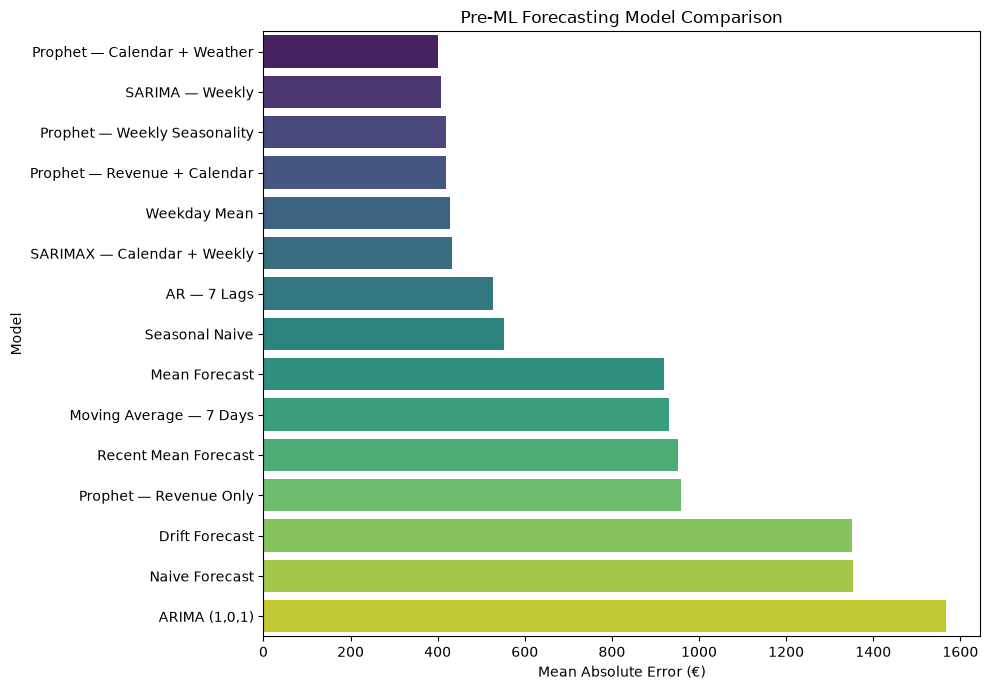

In [71]:
plot_data = (
    pre_ml_leaderboard
    .reset_index()
    .sort_values("MAE", ascending=True)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=plot_data,
    x="MAE",
    y="model",
    hue="model",
    palette="viridis"
)

plt.title("Pre-ML Forecasting Model Comparison")
plt.xlabel("Mean Absolute Error (€)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

`Prophet Calendar + Weather` is currently the best model.

# 8. Random Forest

In [72]:

LAGS = [1, 7, 14, 28]
def make_calendar_features(dates):
    dates = pd.DatetimeIndex(dates)
    return pd.DataFrame({
        "dow": dates.dayofweek,
        "month": dates.month,
        "dayofyear_sin": np.sin(2 * np.pi * dates.dayofyear / 365.25),
        "dayofyear_cos": np.cos(2 * np.pi * dates.dayofyear / 365.25),
        "is_weekend": (dates.dayofweek >= 5).astype(int),
    }, index=dates)

def make_rf_training(history):
    y = history.set_index("date")["revenue"].asfreq("D")
    feats = make_calendar_features(y.index)
    for lag in LAGS:
        feats[f"lag_{lag}"] = y.shift(lag)
    feats["rolling_mean_7"] = y.shift(1).rolling(7).mean()
    data = feats.join(y.rename("target")).dropna()
    return data.drop(columns="target"), data["target"]

def random_forest_forecast(history, forecast_dates):
    X, y = make_rf_training(history)
    model = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                  max_features=0.8, random_state=42, n_jobs=-1)
    model.fit(X, y)
    history_values = list(history.sort_values("date")["revenue"].astype(float))
    preds = []
    for date in pd.to_datetime(forecast_dates):
        row = make_calendar_features([date]).iloc[0].to_dict()
        for lag in LAGS:
            row[f"lag_{lag}"] = history_values[-lag]
        row["rolling_mean_7"] = float(np.mean(history_values[-7:]))
        pred = float(model.predict(pd.DataFrame([row], columns=X.columns))[0])
        preds.append(pred)
        history_values.append(pred)
    return np.asarray(preds)

rf_folds = evaluate_forecaster(random_forest_forecast, train, validation_horizon,
                               initial_train_days, validation_step, "Random Forest — Lag + Calendar")
rf_folds[["model", "origin", "MAE", "RMSE", "MAPE (%)"]]

rf_summary = (
    rf_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

rf_summary


MAE           RMSE        MAPE (%)      
                                  mean    std    mean    std     mean   std
model                                                                      
Random Forest — Lag + Calendar  439.33  85.84  576.33  144.3    15.46  2.82

# 9. Gradient Boosting

In [73]:
def gradient_boosting_forecast(history, forecast_dates):
    X, y = make_rf_training(history)
    model = GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.03, max_depth=2,
        min_samples_leaf=4, random_state=42
    )
    model.fit(X, y)
    history_values = list(history.sort_values("date")["revenue"].astype(float))
    predictions = []
    for date in pd.to_datetime(forecast_dates):
        row = make_calendar_features([date]).iloc[0].to_dict()
        for lag in LAGS:
            row[f"lag_{lag}"] = history_values[-lag]
        row["rolling_mean_7"] = float(np.mean(history_values[-7:]))
        prediction = float(model.predict(pd.DataFrame([row], columns=X.columns))[0])
        predictions.append(prediction)
        history_values.append(prediction)
    return np.asarray(predictions)

gb_folds = evaluate_forecaster(gradient_boosting_forecast, train, validation_horizon,
                              initial_train_days, validation_step, "Gradient Boosting — Lag + Calendar")
gb_folds[["model", "origin", "MAE", "RMSE", "MAPE (%)"]]

gb_summary = (
    gb_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

gb_summary


MAE           RMSE         MAPE (%)  \
                                     mean    std    mean     std     mean   
model                                                                       
Gradient Boosting — Lag + Calendar  429.3  66.26  563.17  125.21    15.17   

                                          
                                     std  
model                                     
Gradient Boosting — Lag + Calendar  2.11

# 10. XBOOST

In [74]:
from xgboost import XGBRegressor

def xgboost_forecast(history, forecast_dates):
    X, y = make_rf_training(history)

    model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=4,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X, y)

    history_values = list(
        history.sort_values("date")["revenue"].astype(float)
    )

    predictions = []

    for date in pd.to_datetime(forecast_dates):

        row = make_calendar_features([date]).iloc[0].to_dict()

        for lag in LAGS:
            row[f"lag_{lag}"] = history_values[-lag]

        row["rolling_mean_7"] = float(
            np.mean(history_values[-7:])
        )

        prediction = float(
            model.predict(
                pd.DataFrame([row], columns=X.columns)
            )[0]
        )

        predictions.append(prediction)
        history_values.append(prediction)

    return np.asarray(predictions)


xgb_folds = evaluate_forecaster(
    xgboost_forecast,
    train,
    validation_horizon,
    initial_train_days,
    validation_step,
    "XGBoost — Lag + Calendar"
)

xgb_folds[["model", "origin", "MAE", "RMSE", "MAPE (%)"]]


xgb_summary = (
    xgb_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

xgb_summary

MAE           RMSE         MAPE (%)      
                            mean    std    mean     std     mean   std
model                                                                 
XGBoost — Lag + Calendar  434.63  82.38  570.16  147.89    15.16  2.22

# 10. Weather, Holiday, Calendar and Promotion Models

In [80]:
WEATHER_COLUMNS = ["temperature_avg_c", "temp_max_c", "temp_min_c", "precipitation_mm", "is_rainy"]
WEATHER_COLUMN_ALIASES = {
    "temperature_avg_c": ["temperature_avg_c", "temperature_c"],
    "temp_max_c": ["temp_max_c"],
    "temp_min_c": ["temp_min_c"],
    "precipitation_mm": ["precipitation_mm"],
    "is_rainy": ["is_rainy"],
}
CONTEXT_COLUMNS = ["dow", "month", "is_weekend", "annual_sin", "annual_cos", "is_holiday", "is_promo_day"]
EXOGENOUS_COLUMNS = WEATHER_COLUMNS + CONTEXT_COLUMNS

def make_weather_context(data):
    frame = data.copy()
    dates = pd.DatetimeIndex(pd.to_datetime(frame["date"]))
    context = pd.DataFrame(index=dates)
    context["dow"] = dates.dayofweek
    context["month"] = dates.month
    context["is_weekend"] = (dates.dayofweek >= 5).astype(int)
    context["annual_sin"] = np.sin(2 * np.pi * dates.dayofyear / 365.25)
    context["annual_cos"] = np.cos(2 * np.pi * dates.dayofyear / 365.25)
    for column in WEATHER_COLUMNS:
        source_column = next((name for name in WEATHER_COLUMN_ALIASES[column] if name in frame.columns), None)
        if source_column is None:
            raise KeyError(f"Required weather feature is missing: {column}. Expected one of {WEATHER_COLUMN_ALIASES[column]}")
        context[column] = pd.to_numeric(frame[source_column], errors="coerce").to_numpy()
    for column in ["is_holiday", "is_promo_day"]:
        if column not in frame.columns:
            raise KeyError(f"Required project feature is missing: {column}")
        context[column] = pd.to_numeric(frame[column], errors="coerce").to_numpy()
    return context[EXOGENOUS_COLUMNS].astype(float)

# Recorded historical weather is used only for weather-informed backtesting.
weather_feature_lookup = make_weather_context(df)

def get_weather_context(dates):
    requested_dates = pd.DatetimeIndex(pd.to_datetime(dates))
    context = weather_feature_lookup.reindex(requested_dates)
    if context.isna().any().any():
        missing = context.index[context.isna().any(axis=1)].strftime("%Y-%m-%d").tolist()
        raise ValueError(f"Missing weather/context inputs for: {missing[:5]}")
    return context[EXOGENOUS_COLUMNS]


In [81]:
def weather_sarimax_forecast(history, forecast_dates):
    y = history.set_index("date")["revenue"].asfreq("D")
    train_exog = get_weather_context(y.index)
    future_exog = get_weather_context(forecast_dates)
    model = SARIMAX(y, exog=train_exog, order=(1, 0, 1), seasonal_order=(1, 0, 1, 7),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False, maxiter=100)
    return np.asarray(fitted.forecast(steps=len(forecast_dates), exog=future_exog), dtype=float)

def make_weather_ml_training(history):
    y = history.set_index("date")["revenue"].asfreq("D")
    features = get_weather_context(y.index).copy()
    for lag in LAGS:
        features[f"lag_{lag}"] = y.shift(lag)
    features["rolling_mean_7"] = y.shift(1).rolling(7).mean()
    model_data = features.join(y.rename("target")).dropna()
    return model_data.drop(columns="target"), model_data["target"]

def recursive_weather_ml_forecast(history, forecast_dates, estimator):
    X, y = make_weather_ml_training(history)
    estimator.fit(X, y)
    history_values = list(history.sort_values("date")["revenue"].astype(float))
    predictions = []
    for date in pd.DatetimeIndex(pd.to_datetime(forecast_dates)):
        row = get_weather_context([date]).iloc[0].to_dict()
        for lag in LAGS:
            row[f"lag_{lag}"] = history_values[-lag]
        row["rolling_mean_7"] = float(np.mean(history_values[-7:]))
        prediction = float(estimator.predict(pd.DataFrame([row], columns=X.columns))[0])
        predictions.append(prediction)
        history_values.append(prediction)
    return np.asarray(predictions)

def weather_random_forest_forecast(history, forecast_dates):
    estimator = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.8, random_state=42, n_jobs=-1)
    return recursive_weather_ml_forecast(history, forecast_dates, estimator)

def weather_gradient_boosting_forecast(history, forecast_dates):
    estimator = GradientBoostingRegressor(n_estimators=200, learning_rate=0.03, max_depth=2, min_samples_leaf=4, random_state=42)
    return recursive_weather_ml_forecast(history, forecast_dates, estimator)

weather_folds = pd.concat([
    evaluate_forecaster(weather_sarimax_forecast, train, validation_horizon, initial_train_days, validation_step, "SARIMAX — Weather + Calendar + Holiday + Promotion"),
    evaluate_forecaster(weather_random_forest_forecast, train, validation_horizon, initial_train_days, validation_step, "Random Forest — Weather + Calendar + Holiday + Promotion"),
    evaluate_forecaster(weather_gradient_boosting_forecast, train, validation_horizon, initial_train_days, validation_step, "Gradient Boosting — Weather + Calendar + Holiday + Promotion"),
], ignore_index=True)
weather_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]].agg(["mean", "std"]).round(2)


/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: Conv

MAE           RMSE  \
                                                      mean    std    mean   
model                                                                       
Gradient Boosting — Weather + Calendar + Holida...  438.31  78.59  565.51   
Random Forest — Weather + Calendar + Holiday + ...  429.93  86.28  554.02   
SARIMAX — Weather + Calendar + Holiday + Promotion  448.43  70.63  587.57   

                                                           MAPE (%)        
                                                       std     mean   std  
model                                                                      
Gradient Boosting — Weather + Calendar + Holida...  126.84    15.57  2.86  
Random Forest — Weather + Calendar + Holiday + ...  143.11    15.29  2.92  
SARIMAX — Weather + Calendar + Holiday + Promotion  119.87    15.86  2.76

### 10.1 Live Weather API for Future Predictions

In [82]:
# Set these to the restaurant's actual location before creating a real future forecast.
RESTAURANT_LATITUDE = None
RESTAURANT_LONGITUDE = None
PLANNED_HOLIDAY_DATES = []  # Example: ["2026-01-01", "2026-01-06"]
PLANNED_PROMOTION_DATES = []  # Example: ["2026-01-10", "2026-01-17"]

def fetch_openmeteo_daily_weather(latitude, longitude, start_date, end_date):
    import requests
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum",
        "timezone": "auto",
        "start_date": pd.Timestamp(start_date).date().isoformat(),
        "end_date": pd.Timestamp(end_date).date().isoformat(),
    }
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    daily = response.json()["daily"]
    weather = pd.DataFrame({
        "date": pd.to_datetime(daily["time"]),
        "temperature_avg_c": daily["temperature_2m_mean"],
        "temp_max_c": daily["temperature_2m_max"],
        "temp_min_c": daily["temperature_2m_min"],
        "precipitation_mm": daily["precipitation_sum"],
    })
    weather["is_rainy"] = (weather["precipitation_mm"] > 0).astype(int)
    holiday_dates = pd.to_datetime(PLANNED_HOLIDAY_DATES)
    promotion_dates = pd.to_datetime(PLANNED_PROMOTION_DATES)
    weather["is_holiday"] = weather["date"].isin(holiday_dates).astype(int)
    weather["is_promo_day"] = weather["date"].isin(promotion_dates).astype(int)
    return make_weather_context(weather)

def add_api_weather_to_lookup(future_dates):
    if RESTAURANT_LATITUDE is None or RESTAURANT_LONGITUDE is None:
        raise ValueError("Set RESTAURANT_LATITUDE and RESTAURANT_LONGITUDE before requesting future weather.")
    api_context = fetch_openmeteo_daily_weather(
        RESTAURANT_LATITUDE, RESTAURANT_LONGITUDE, future_dates.min(), future_dates.max()
    )
    global weather_feature_lookup
    weather_feature_lookup = pd.concat([weather_feature_lookup, api_context]).loc[lambda x: ~x.index.duplicated(keep="last")].sort_index()


# 11. Model Comparison and Selection

In [ ]:
all_folds = pd.concat(
    [
        baseline_folds,
        traditional_folds,
        prophet_all_folds,
        sarimax_folds,
        rf_folds,
        gb_folds,
        xgb_folds
    ],
    ignore_index=True
)


model_comparison = (
    all_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
)

model_comparison.columns = [
    f"{metric}_{stat}"
    for metric, stat in model_comparison.columns
]

model_comparison = (
    model_comparison
    .sort_values("MAE_mean")
    .round(2)
)

comparison_table = (
    model_comparison
    .reset_index()
    .rename(columns={
        "model": "Model",
        "MAE_mean": "MAE (€)",
        "RMSE_mean": "RMSE (€)",
        "MAPE (%)_mean": "MAPE (%)",
        "MAE_std": "MAE SD (€)",
        "RMSE_std": "RMSE SD (€)",
        "MAPE (%)_std": "MAPE SD (%)",
    })
)

comparison_table

In [ ]:
validation_stability = (
    all_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .std()
    .sort_values("MAE")
    .round(2)
)

validation_stability

In [ ]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=comparison_table.sort_values("MAE (€)"),
    x="MAE (€)",
    y="Model",
    hue="Model",
    legend=False,
    palette="viridis"
)

plt.title("All Forecasting Models: Lower MAE is Better")
plt.xlabel("Mean MAE from Rolling Validation (€)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

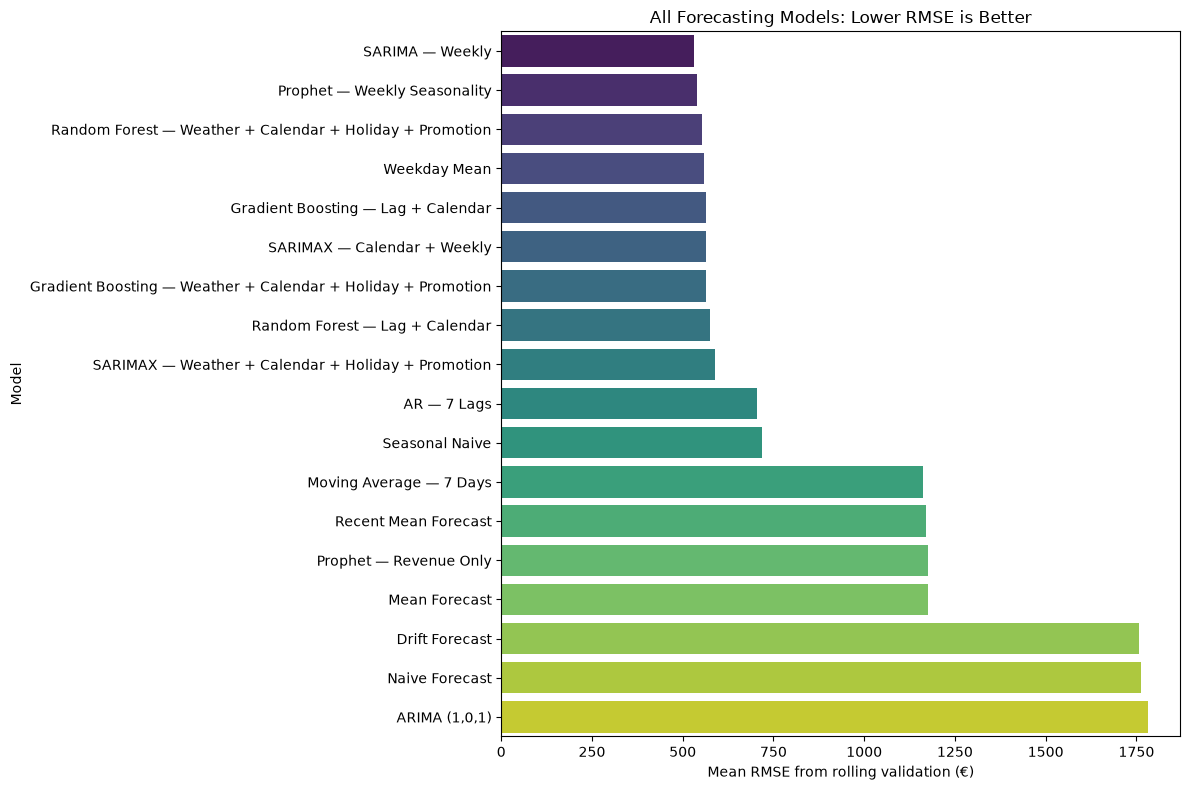

In [85]:
# Every candidate, including weather-aware models, must be compared on the same validation folds.
all_folds = pd.concat([baseline_folds, traditional_folds, prophet_folds, sarimax_folds, rf_folds, gb_folds, weather_folds], ignore_index=True)
model_comparison = (all_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
                    .agg(["mean", "std"]))
model_comparison.columns = [f"{metric}_{stat}" for metric, stat in model_comparison.columns]
model_comparison = model_comparison.sort_values("MAE_mean").round(2)

comparison_table = (model_comparison.reset_index()
                    .rename(columns={
                        "model": "Model",
                        "MAE_mean": "MAE (€)",
                        "RMSE_mean": "RMSE (€)",
                        "MAPE (%)_mean": "MAPE (%)",
                        "MAE_std": "MAE SD (€)",
                        "RMSE_std": "RMSE SD (€)",
                        "MAPE (%)_std": "MAPE SD (%)",
                    })
                    )

plt.figure(figsize=(12, 8))
sns.barplot(
    data=comparison_table.sort_values("RMSE (€)"),
    x="RMSE (€)",
    y="Model",
    hue="Model",
    legend=False,
    palette="viridis"
)
plt.title("All Forecasting Models: Lower RMSE is Better")
plt.xlabel("Mean RMSE from rolling validation (€)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


In [87]:
forecast_functions = {
    **baseline_forecasters,
    **traditional_forecasters,
    "Prophet — Revenue Only": prophet_revenue_only,
    "Prophet — Weekly Seasonality": prophet_calendar,
    "SARIMAX — Calendar + Weekly": sarimax_forecast,
    "Random Forest — Lag + Calendar": random_forest_forecast,
    "Gradient Boosting — Lag + Calendar": gradient_boosting_forecast,
    "SARIMAX — Weather + Calendar + Holiday + Promotion": weather_sarimax_forecast,
    "Random Forest — Weather + Calendar + Holiday + Promotion": weather_random_forest_forecast,
    "Gradient Boosting — Weather + Calendar + Holiday + Promotion": weather_gradient_boosting_forecast,
}
best_model_name = model_comparison.index[0]
best_forecaster = forecast_functions[best_model_name]
print("Selected by lowest mean rolling-validation MAE:", best_model_name)
print("Mean validation MAE (€):", model_comparison.loc[best_model_name, "MAE_mean"])


Selected by lowest mean rolling-validation MAE: SARIMA — Weekly
Mean validation MAE (€): 407.98


# 12. Final Test Evaluation

In [88]:
test_dates = test["date"].reset_index(drop=True)
final_predictions = best_forecaster(train, test_dates)
final_metrics = calculate_metrics(test["revenue"].to_numpy(), final_predictions)
print("Final test period:", test_dates.min().date(), "to", test_dates.max().date())
print("Forecast horizon:", len(test_dates), "days")
print("Selected model:", best_model_name)
final_metrics


Final test period: 2025-10-01 to 2025-12-31
Forecast horizon: 92 days
Selected model: SARIMA — Weekly


{'MAE': 409.6805139750573,
 'RMSE': np.float64(528.9980685205999),
 'MAPE (%)': np.float64(17.05607485328714)}

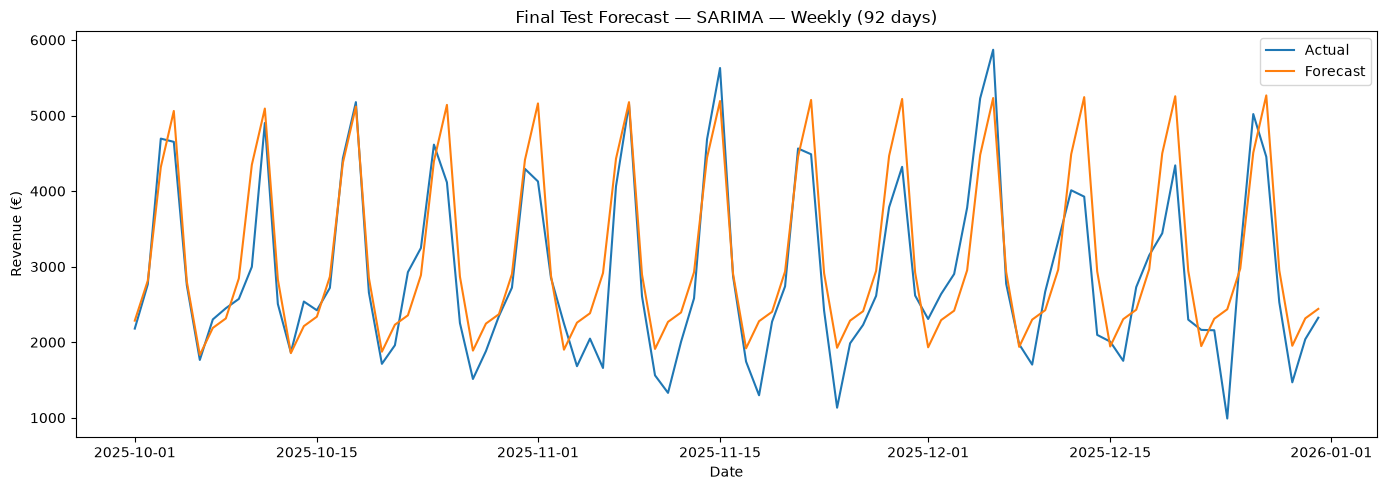

,date,actual_revenue,forecast_revenue
0,2025-10-01,2179.97,2285.030582
1,2025-10-02,2767.21,2814.547262
2,2025-10-03,4694.14,4316.417098
3,2025-10-04,4651.44,5059.827287
4,2025-10-05,2755.26,2802.591080


In [89]:
test_results = pd.DataFrame({"date": test_dates, "actual_revenue": test["revenue"].to_numpy(),
                             "forecast_revenue": final_predictions})
plt.figure(figsize=(14, 5))
plt.plot(test_results["date"], test_results["actual_revenue"], label="Actual", linewidth=1.5)
plt.plot(test_results["date"], test_results["forecast_revenue"], label="Forecast", linewidth=1.5)
plt.title(f"Final Test Forecast — {best_model_name} (92 days)")
plt.xlabel("Date")
plt.ylabel("Revenue (€)")
plt.legend()
plt.tight_layout()
plt.show()
test_results.head()


# 13. Forecast Future Revenue

In [90]:
# Fourteen days fits within a typical weather-forecast API window.
future_horizon = 14
full_history = df[["date", "revenue"]].copy()
future_dates = pd.date_range(full_history["date"].max() + pd.Timedelta(days=1), periods=future_horizon, freq="D")
# Weather-aware models need forecast weather, known holidays, and planned promotion dates.
if "Weather +" in best_model_name:
    add_api_weather_to_lookup(future_dates)
future_values = best_forecaster(full_history, pd.Series(future_dates))
future_forecast = pd.DataFrame({"date": future_dates, "forecast_revenue": future_values})
future_forecast.head()


,date,forecast_revenue
0,2026-01-01,2939.361900
1,2026-01-02,4408.671210
2,2026-01-03,4714.178504
3,2026-01-04,2574.982516
4,2026-01-05,1824.201438


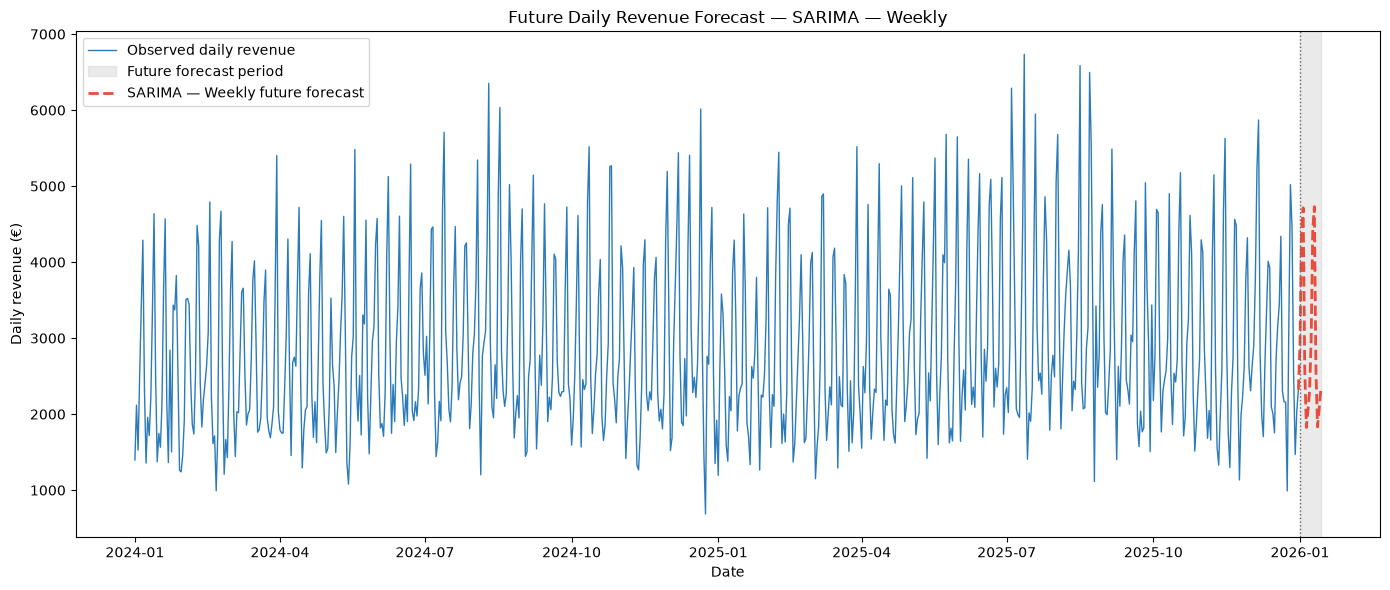

In [91]:
# ============================================
# FINAL FUTURE-REVENUE FORECAST PLOT
# ============================================
plt.figure(figsize=(14, 6))

plt.plot(
    full_history["date"],
    full_history["revenue"],
    color="#2b7bba",
    linewidth=1,
    label="Observed daily revenue"
)

plt.axvspan(
    future_forecast["date"].iloc[0],
    future_forecast["date"].iloc[-1],
    color="#d9d9d9",
    alpha=0.55,
    label="Future forecast period"
)

forecast_plot_dates = pd.concat([
    full_history[["date"]].tail(1),
    future_forecast[["date"]]
], ignore_index=True)
forecast_plot_values = np.concatenate([
    full_history["revenue"].tail(1).to_numpy(),
    future_forecast["forecast_revenue"].to_numpy()
])

plt.plot(
    forecast_plot_dates["date"],
    forecast_plot_values,
    color="#e74c3c",
    linestyle="--",
    linewidth=2,
    label=f"{best_model_name} future forecast"
)

plt.axvline(future_forecast["date"].iloc[0], color="#666666", linestyle=":", linewidth=1)
plt.title(f"Future Daily Revenue Forecast — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Daily revenue (€)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


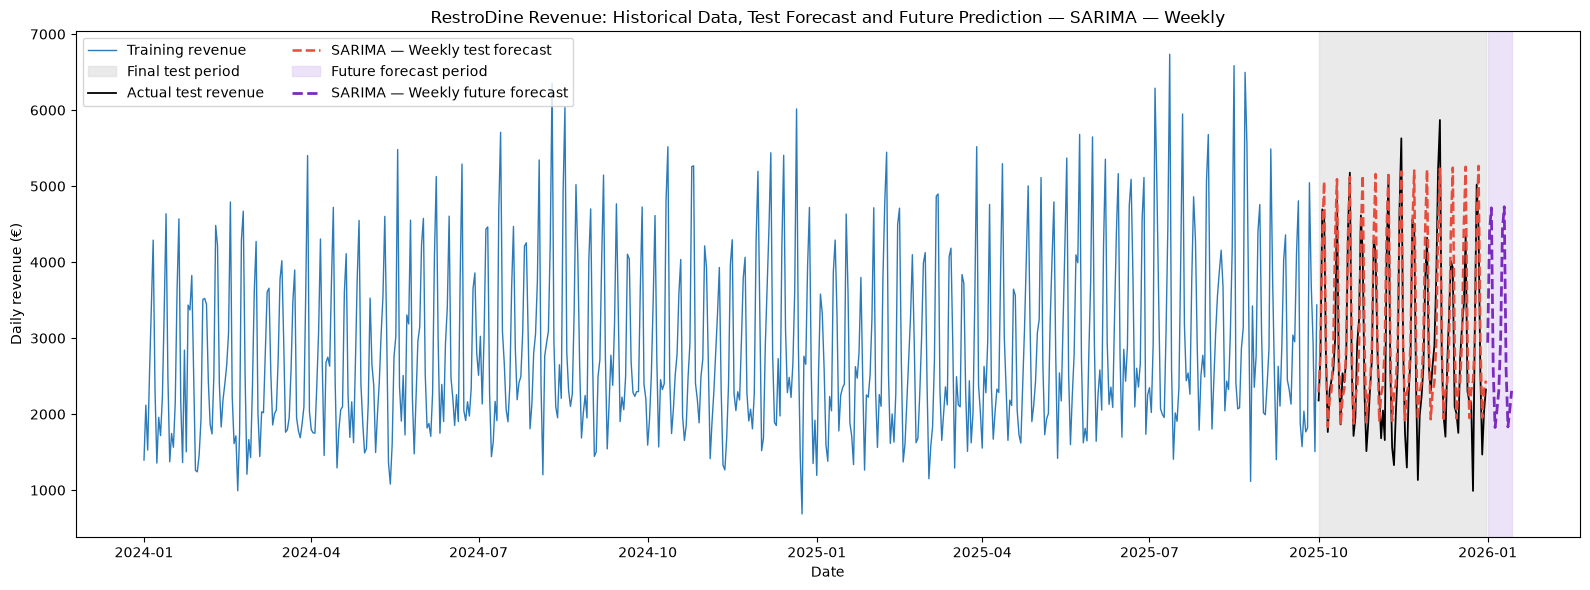

In [92]:
plt.figure(figsize=(16, 6))

# Observed revenue: train in blue, final test actuals in black.
plt.plot(train["date"], train["revenue"], color="#2b7bba", linewidth=1, label="Training revenue")
plt.axvspan(test["date"].iloc[0], test["date"].iloc[-1], color="#d9d9d9", alpha=0.55, label="Final test period")
plt.plot(test["date"], test["revenue"], color="black", linewidth=1.3, label="Actual test revenue")

# Selected-model holdout forecast.
plt.plot(test_results["date"], test_results["forecast_revenue"], color="#e74c3c", linestyle="--", linewidth=1.8, label=f"{best_model_name} test forecast")

# Future forecast begins immediately after the last observed day.
plt.axvspan(future_forecast["date"].iloc[0], future_forecast["date"].iloc[-1], color="#d9c2f0", alpha=0.45, label="Future forecast period")
plt.plot(future_forecast["date"], future_forecast["forecast_revenue"], color="#7b2cbf", linestyle="--", linewidth=2, label=f"{best_model_name} future forecast")

plt.title(f"RestroDine Revenue: Historical Data, Test Forecast and Future Prediction — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Daily revenue (€)")
plt.legend(loc="upper left", ncol=2)
plt.tight_layout()
plt.show()


## Next Steps to Run the Final Forecast

1. Run this notebook from top to bottom through the model-comparison table.
2. Select the model with the lowest rolling-validation MAE; weather-aware models are now included in that comparison.
3. Set `RESTAURANT_LATITUDE` and `RESTAURANT_LONGITUDE` in the Live Weather API cell.
4. Enter dates for any known holidays and planned promotions.
5. Re-run the final-test, future-forecast, and final-chart cells.

For a real operational forecast, use the next 14 days because the model needs future weather supplied by the API. The 92-day period remains the final historical test used to assess the selected model.

### How to interpret the result

The final chart combines historical revenue, the holdout-period forecast, and the future revenue prediction. The selected weather-aware model uses past revenue, calendar variables, holiday dates, promotion plans, and weather forecast inputs.
